# Regime-aware forecasting of SPX relative bid-ask spread — revised

**相对原版的主要修改**

1. **补上 `pandemic_dummy`**（2020-03-01 ~ 2022-12-31，与 Pre 中的定义一致）。原 notebook 未定义该变量，无法从头运行。
2. **HMM 改为真正的样本外 + 前向滤波**：每次只用 `[i-W, i)` 训练，用 forward filtering 得到 `[i, i+STEP)` 的状态概率（t 时刻只用到 ≤ t 的数据）。原版对训练窗口内的数据做 forward-backward 平滑，存在未来信息泄露。
3. **清洗顺序**：先在连续序列上计算所有滞后 / 滚动特征，不再删行（原版先删行再 `shift`，`lag1` 不一定是前一日）。异常值改为用**过去 252 日**的 1%/99% 分位数标记，且只从**训练集**中剔除，测试集全部保留。缺失值只用 `ffill`，不再用双边插值。
4. **结构性断点**：rel_spread 在 2011-06（约 6 倍）和 2016-12（约 4 倍）出现两次跳升，疑似 Bloomberg 指数报价口径变化。新增诊断和分时段评估，并提供 `SAMPLE_START` 开关做稳健性检验。
5. **共线性**：`prob_state_0_lag1 + prob_state_1_lag1 ≡ 1`，只保留 `prob_state_1_lag1`。
6. **滚动 CV**：每 21 天重训一次（原来每天重训），修正 LightGBM 参数（`subsample_freq`、`num_leaves`），固定随机种子，按窗口单独记录 train/val RMSE。
7. **评估**：新增相对 Persistence 的 skill score、分时段指标；DM 检验加入 Newey-West + HLN 修正，并对所有模型与 Persistence 比较。
8. **SHAP** 改为解释最后一个滚动窗口里实际用于预测的 XGB 模型；**经济评估**改为基于预测的择时交易规则（原版累计和对比没有信息量）。
9. **预测目标改为 log(rel_spread)**：spread 右偏且跨越两个量级，在 log 空间建模后再 `exp` 回水平值评估。保留了水平目标的 Linear 作为对照。
10. **新增第 12、13 节，评估 HMM 的增量价值**：(a) 消融实验，去掉 HMM 特征重新跑；(b) 三种改进版 HMM（局部标准化输入、spread 动态输入、regime 交互项）；(c) 用 HMM 状态构造预测区间，与 EWMA 残差波动率比较。
11. **删除休市日的伪造行**：Bloomberg 把约 250 个交易所休市日用前一日数据原样填充（收盘价、成交量、报价完全相同），这些行会虚增 spread 的持续性。
12. **新增第 14 节扩展**：HAR 型长记忆特征（过去 5/22/63 日均值）、日历特征（节假日前后、月初月末、期权到期日、星期几），以及一个新的预测任务——预测次日 spread 是否出现尖峰（分类问题）。
13. 其他：HMM 的偏态特征改用 `log`（`log1p` 对 1e-3 量级的数几乎没有变换）；Amihud 用当日成交量；修复按状态分组时 `astype(int)` 遇 NaN 的问题；去掉全局 `warnings.filterwarnings('ignore')`。

In [1]:
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
import shap
from hmmlearn.hmm import GaussianHMM
from scipy import stats
from scipy.special import logsumexp
from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             mean_absolute_error, root_mean_squared_error)
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import acf

sns.set_style('darkgrid')
pd.set_option('display.width', 160)
warnings.filterwarnings('ignore', message=".*'eval_set' is deprecated.*")   # lightgbm>=4.6 API rename only

In [2]:
# ---- configuration ----
DATA_PATH     = '../data/data.csv'
SAMPLE_START  = None            # e.g. '2017-06-01' to use only the post-break sample
PANDEMIC      = ('2020-03-01', '2022-12-31')
OUTLIER_WIN   = 252             # past window for outlier quantiles
OUTLIER_Q     = 0.01
HMM_WINDOW    = 756             # ~3 years
HMM_STEP      = 21              # refit monthly
K_HMM         = 2
TRAIN_WINDOW  = 500
VAL_WINDOW    = 50
CV_STEP       = 21              # refit monthly, forecast next 21 days
SEED          = 42

## 0. Load data

In [3]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
if np.issubdtype(df['Dates'].dtype, np.number):
    df['Date'] = pd.to_datetime(df['Dates'], unit='D', origin='1899-12-30')   # Excel serial
else:
    df['Date'] = pd.to_datetime(df['Dates'])
df = df.sort_values('Date').set_index('Date')

df = df.dropna(subset=['PX_BID', 'PX_ASK', 'PX_MID', 'PX_LAST', 'PX_VOLUME'])
valid = (df['PX_ASK'] > df['PX_BID']) & (df['PX_BID'] <= df['PX_MID']) & (df['PX_MID'] <= df['PX_ASK'])
print(f"Invalid quotes removed (data errors): {(~valid).sum()} of {len(df)}")
df = df[valid].copy()

# exchange holidays are filled by the vendor with a verbatim copy of the previous day -> not real observations
stale = (df['PX_LAST'].diff() == 0) & (df['PX_VOLUME'].diff() == 0) & (df['PX_BID'].diff() == 0)
print(f"Stale holiday rows removed (copy of previous day): {stale.sum()}, e.g. {df.index[stale][:3].strftime('%Y-%m-%d').tolist()}")
df = df[~stale].copy()
if SAMPLE_START is not None:
    df = df.loc[SAMPLE_START:].copy()
print("Date range:", df.index.min().date(), "to", df.index.max().date(), "| rows:", len(df))
print("Gaps between rows (calendar days):", df.index.to_series().diff().dt.days.value_counts().sort_index().to_dict())

Invalid quotes removed (data errors): 1 of 7229
Stale holiday rows removed (copy of previous day): 256, e.g. ['1998-04-10', '1998-05-25', '1998-07-03']
Date range: 1998-03-02 to 2025-11-13 | rows: 6972
Gaps between rows (calendar days): {1.0: 5460, 2.0: 66, 3.0: 1258, 4.0: 184, 5.0: 2, 6.0: 1}


## 1. Feature engineering (on the contiguous series — no rows are deleted)

All predictors used in the regression are known at the close of day t-1.

NaNs before ffill: 1220
Rows flagged as outliers (excluded from training only): 527


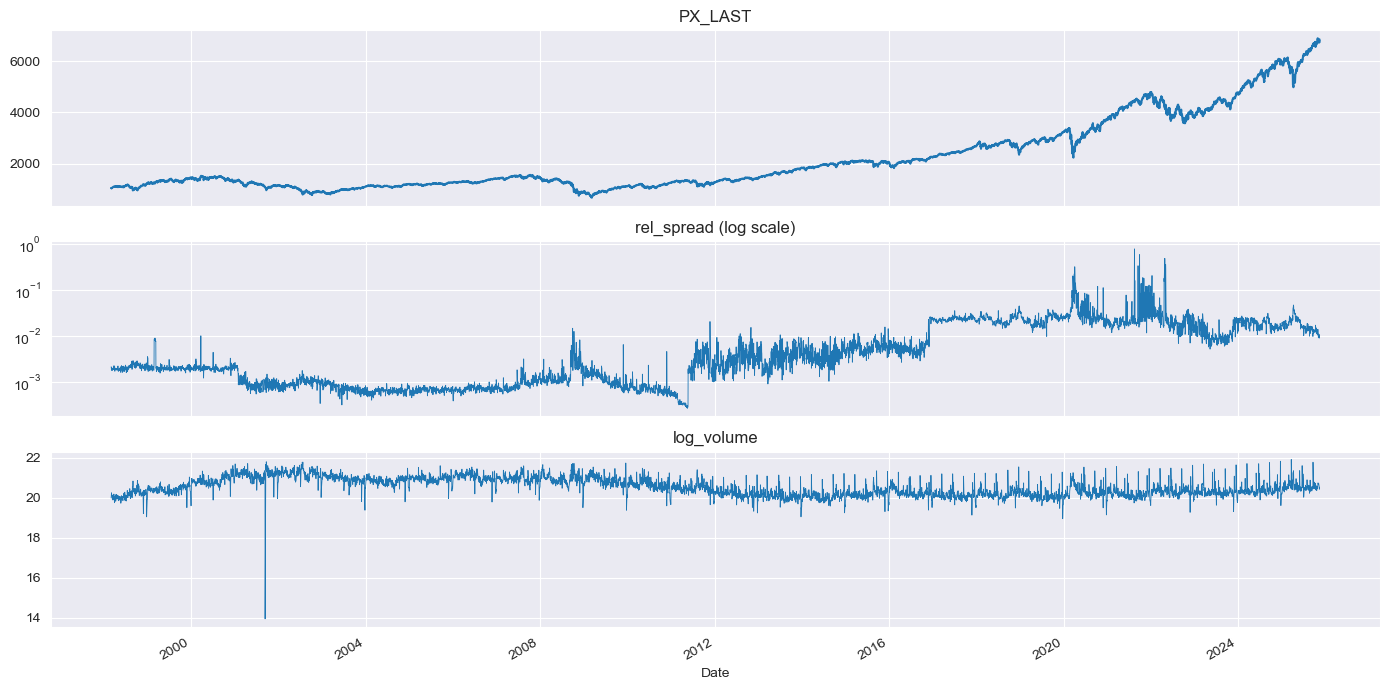

In [4]:
df['return']     = df['PX_LAST'] / df['PX_CLOSE_1D'] - 1
df['abs_return'] = df['return'].abs()
df['rel_spread'] = (df['PX_ASK'] - df['PX_BID']) / df['PX_MID']
df['log_volume'] = np.log(df['PX_VOLUME'].where(df['PX_VOLUME'] > 0))
df['pe_diff']    = df['BEST_PE_RATIO'].diff()
df['ami']        = df['abs_return'] / df['PX_VOLUME'] * 1e9          # Amihud: |r_t| / Vol_t (scaled)

# already lagged (use information up to t-1)
df['rv_5']         = df['return'].shift(1).rolling(5, min_periods=3).std() * np.sqrt(252)
df['rv_21']        = df['return'].shift(1).rolling(21, min_periods=10).std() * np.sqrt(252)
df['price_trend']  = df['PX_LAST'].shift(1).rolling(5).mean() / df['PX_LAST'].shift(1).rolling(20).mean() - 1
df['volume_trend'] = df['PX_VOLUME'].shift(1).rolling(5).mean() / df['PX_VOLUME'].shift(1).rolling(20).mean() - 1
for l in [1, 2, 3, 5]:
    df[f'spread_lag{l}'] = df['rel_spread'].shift(l)
for c in ['log_volume', 'ami', 'pe_diff']:
    df[f'{c}_lag1'] = df[c].shift(1)

df['pandemic_dummy'] = ((df.index >= PANDEMIC[0]) & (df.index <= PANDEMIC[1])).astype(int)

# HAR-style long-memory features: average log spread over the past 5 / 22 / 63 days (known at t-1)
for w in [5, 22, 63]:
    df[f'har_{w}'] = np.log(df['rel_spread']).shift(1).rolling(w).mean()

# calendar features (the exchange calendar is known in advance, so using the next trading date is not look-ahead)
dates = df.index.to_series()
gap_next, gap_prev = (dates.shift(-1) - dates).dt.days, (dates - dates.shift(1)).dt.days
wd = df.index.weekday
df['pre_holiday']  = (((wd < 4) & (gap_next > 1)) | ((wd == 4) & (gap_next > 3))).astype(int)
df['post_holiday'] = (((wd > 0) & (gap_prev > 1)) | ((wd == 0) & (gap_prev > 3))).astype(int)
month = df.index.to_period('M').to_series(index=df.index)
df['month_end']    = (month != month.shift(-1)).astype(int)
df['month_start']  = (month != month.shift(1)).astype(int)
third_friday = (wd == 4) & (df.index.day >= 15) & (df.index.day <= 21)
df['opex']          = third_friday.astype(int)
df['quad_witching'] = (third_friday & df.index.month.isin([3, 6, 9, 12])).astype(int)
for k, name in enumerate(['mon', 'tue', 'wed', 'thu']):
    df[f'dow_{name}'] = (wd == k).astype(int)

# causal fill only (no two-sided interpolation)
num_cols = df.select_dtypes('number').columns
print("NaNs before ffill:", int(df[num_cols].isna().sum().sum()))
df[num_cols] = df[num_cols].ffill()

# outlier flags from PAST quantiles only; used to exclude rows from training, never from testing
def past_quantile_flag(s, win=OUTLIER_WIN, q=OUTLIER_Q):
    past = s.shift(1).rolling(win, min_periods=win // 2)
    return (s < past.quantile(q)) | (s > past.quantile(1 - q))

df['spread_outlier'] = past_quantile_flag(df['rel_spread'])
df['volume_outlier'] = past_quantile_flag(df['log_volume'])
df['train_ok'] = ~(df['spread_outlier'] | df['volume_outlier'])
print(f"Rows flagged as outliers (excluded from training only): {(~df['train_ok']).sum()}")

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
df['PX_LAST'].plot(ax=axes[0], title='PX_LAST')
df['rel_spread'].plot(ax=axes[1], title='rel_spread (log scale)', logy=True, lw=0.6)
df['log_volume'].plot(ax=axes[2], title='log_volume', lw=0.6)
plt.tight_layout(); plt.show()

## 2. Structural break in the spread series

The level of `rel_spread` jumps roughly 6x in June 2011 and 4x in December 2016, within a single month each time.
SPX liquidity did not deteriorate like that, so these jumps most likely reflect changes in how the data vendor computes the index bid/ask.
Any "regime" found below must be read with this in mind; set `SAMPLE_START` (e.g. `'2017-01-01'`) for a robustness check.

In [5]:
yearly = df.groupby(df.index.year)['rel_spread'].agg(['median', 'mean', 'count'])
print(yearly.round(5).to_string())

# largest month-over-month changes in the monthly median spread
monthly = df['rel_spread'].resample('ME').median()
ratio = (monthly / monthly.shift(1)).dropna()
print("Largest month-over-month jumps in median rel_spread:")
print(ratio.sort_values(ascending=False).head(3).round(2).to_string())

       median     mean  count
Date                         
1998  0.00208  0.00211    213
1999  0.00197  0.00226    252
2000  0.00195  0.00202    252
2001  0.00092  0.00101    249
2002  0.00097  0.00097    252
2003  0.00075  0.00076    252
2004  0.00063  0.00064    252
2005  0.00067  0.00067    252
2006  0.00069  0.00071    251
2007  0.00083  0.00091    251
2008  0.00119  0.00182    253
2009  0.00111  0.00121    252
2010  0.00068  0.00072    252
2011  0.00172  0.00213    252
2012  0.00304  0.00363    250
2013  0.00345  0.00382    252
2014  0.00370  0.00399    251
2015  0.00569  0.00595    252
2016  0.00534  0.00700    252
2017  0.02338  0.02355    251
2018  0.02267  0.02337    251
2019  0.02305  0.02307    252
2020  0.02657  0.03903    253
2021  0.02052  0.03843    252
2022  0.02201  0.03471    251
2023  0.01021  0.01232    250
2024  0.01876  0.01907    252
2025  0.01662  0.01830    218
Largest month-over-month jumps in median rel_spread:
Date
2011-06-30    6.34
2021-10-31    3.88
2016

## 3. KMeans (exploratory, full-sample / in-sample, outlier days excluded — not used for forecasting)

Features: ['rv_5', 'log_volume', 'rel_spread', 'ami', 'pe_diff', 'price_trend'] | best K (silhouette) = 5


Silhouette 0.250 | Davies-Bouldin 1.322 | Calinski-Harabasz 1210.1


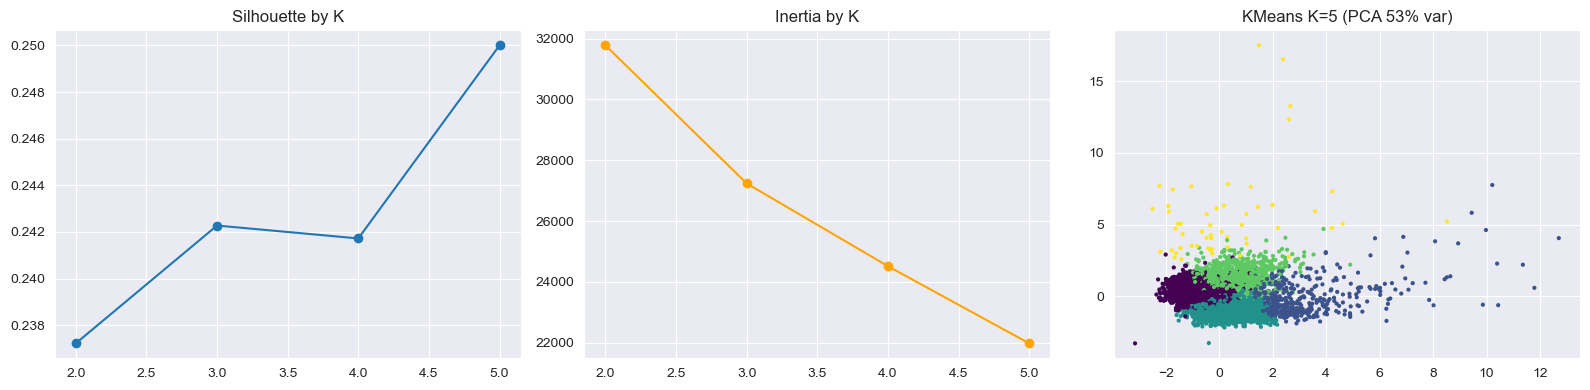

,rv_5,log_volume,rel_spread,ami,pe_diff,price_trend
cluster,,,,,,
0,0.105948,20.179699,0.012599,0.006218,-0.001466,0.009308
1,0.424688,20.937500,0.006505,0.013766,0.059928,-0.038692
2,0.151527,20.942779,0.001516,0.005374,-0.012581,0.004133
3,0.174630,20.331769,0.012550,0.022583,0.012966,-0.001843
4,0.257549,20.341002,0.126254,0.017718,0.091217,0.004217


In [6]:
cluster_features = ['rv_5', 'log_volume', 'rel_spread', 'ami', 'pe_diff', 'price_trend']
X_cluster = df.loc[df['train_ok'], cluster_features].dropna()

corr = X_cluster.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
drop = [c for c in upper.columns if (upper[c] > 0.8).any()]
cluster_opt = [f for f in cluster_features if f not in drop]
Xs = StandardScaler().fit_transform(X_cluster[cluster_opt])

K_list = [2, 3, 4, 5]
sil, inertia = [], []
for k in K_list:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xs)
    sil.append(silhouette_score(Xs, km.labels_)); inertia.append(km.inertia_)
best_k = K_list[int(np.argmax(sil))]

km = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit(Xs)
labels_km = km.labels_
print(f"Features: {cluster_opt} | best K (silhouette) = {best_k}")
print(f"Silhouette {silhouette_score(Xs, labels_km):.3f} | Davies-Bouldin {davies_bouldin_score(Xs, labels_km):.3f} "
      f"| Calinski-Harabasz {calinski_harabasz_score(Xs, labels_km):.1f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(K_list, sil, marker='o'); axes[0].set_title('Silhouette by K')
axes[1].plot(K_list, inertia, marker='o', color='orange'); axes[1].set_title('Inertia by K')
pca = PCA(n_components=2).fit(Xs); P = pca.transform(Xs)
axes[2].scatter(P[:, 0], P[:, 1], c=labels_km, s=4, cmap='viridis')
axes[2].set_title(f'KMeans K={best_k} (PCA {pca.explained_variance_ratio_.sum():.0%} var)')
plt.tight_layout(); plt.show()

display(X_cluster[cluster_opt].assign(cluster=labels_km).groupby('cluster').mean())

## 4. Rolling HMM — out-of-sample, filtered probabilities

For each refit date *i*: fit on `[i-W, i)`, then run the forward filter over `[i-W, i+STEP)` and keep rows `[i, i+STEP)`.
P(state at t) therefore only uses observations up to t, and the model never saw those rows during fitting.
States are relabelled by the fitted mean of the spread feature (state 0 = low spread, state 1 = high spread).

In [7]:
def filtered_probs(model, X):
    # forward algorithm: P(s_t | x_1..x_t)
    logB = np.column_stack([multivariate_normal(model.means_[k], model.covars_[k], allow_singular=True).logpdf(X)
                            for k in range(model.n_components)])
    with np.errstate(divide='ignore'):                    # log(0) = -inf is fine here
        logA, logpi = np.log(model.transmat_), np.log(model.startprob_)
    out = np.empty_like(logB)
    la = logpi + logB[0]
    out[0] = la - logsumexp(la)
    for t in range(1, len(X)):
        la = logsumexp(out[t - 1][:, None] + logA, axis=0) + logB[t]
        out[t] = la - logsumexp(la)
    return np.exp(out)

df['log_rel_spread'] = np.log(df['rel_spread'])
df['log_rv_5']       = np.log(df['rv_5'].clip(lower=1e-3))   # rv_5 can be exactly 0
df['log_ami']        = np.log(df['ami'] + 1e-3)
hmm_features = ['log_rel_spread', 'log_rv_5', 'log_volume', 'log_ami', 'price_trend']

def run_hmm(F, K=K_HMM, sort_col=0, window=HMM_WINDOW, step=HMM_STEP):
    # rolling out-of-sample HMM; returns filtered P(state_t | x_1..x_t), states sorted by the mean of column sort_col
    F = F.dropna()
    X, n = F.values, len(F)
    P = np.full((n, K), np.nan)
    transmats, n_fail = [], 0
    for i in range(window, n, step):
        end = min(i + step, n)
        scaler = StandardScaler().fit(X[i - window:i])
        train = scaler.transform(X[i - window:i])
        try:
            m = GaussianHMM(n_components=K, covariance_type='full', n_iter=200, random_state=SEED).fit(train)
        except Exception as e:
            n_fail += 1
            print(f"HMM fit failed at {F.index[i].date()}: {e}")
            continue
        order = np.argsort(m.means_[:, sort_col])
        P[i:end] = filtered_probs(m, scaler.transform(X[i - window:end]))[window:][:, order]
        transmats.append(m.transmat_[np.ix_(order, order)])
    # sanity check: forward filter at the last step equals hmmlearn's smoothed posterior at the last step
    assert np.allclose(filtered_probs(m, train)[-1], m.predict_proba(train)[-1], atol=1e-6)
    return pd.DataFrame(P, index=F.index, columns=[f'prob_state_{k}' for k in range(K)]), transmats, n_fail

probs, transmats, n_fail = run_hmm(df[hmm_features])
df[probs.columns] = probs
P = df[[f'prob_state_{k}' for k in range(K_HMM)]]
df['hmm_state'] = np.where(P.notna().all(axis=1), P.fillna(-1).values.argmax(axis=1), np.nan)

print(f"Windows: {len(transmats)} fitted, {n_fail} failed | rows with OOS state: {df['hmm_state'].notna().sum()}")
print("Average transition matrix across windows:\n", np.mean(transmats, axis=0).round(3))
display(df.groupby('hmm_state')[['rel_spread', 'rv_5', 'log_volume']].agg(['mean', 'median', 'count']))

df['period'] = pd.cut(df.index.year, bins=5, labels=['P1', 'P2', 'P3', 'P4', 'P5'])
print("State share by period:")
print(df.dropna(subset=['hmm_state']).groupby('period', observed=True)['hmm_state']
        .value_counts(normalize=True).unstack(fill_value=0).round(3))

Windows: 296 fitted, 0 failed | rows with OOS state: 6196
Average transition matrix across windows:
 [[0.954 0.046]
 [0.057 0.943]]


rel_spread                      rv_5                 log_volume                 
                mean    median count      mean    median count       mean     median count
hmm_state                                                                                 
0.0         0.006891  0.001017  3129  0.131155  0.112316  3129  20.622482  20.606011  3129
1.0         0.014715  0.005990  3067  0.176143  0.138366  3067  20.430866  20.331948  3067

State share by period:


hmm_state    0.0    1.0
period                 
P1         0.984  0.016
P2         0.520  0.480
P3         0.426  0.574
P4         0.304  0.696
P5         0.519  0.481


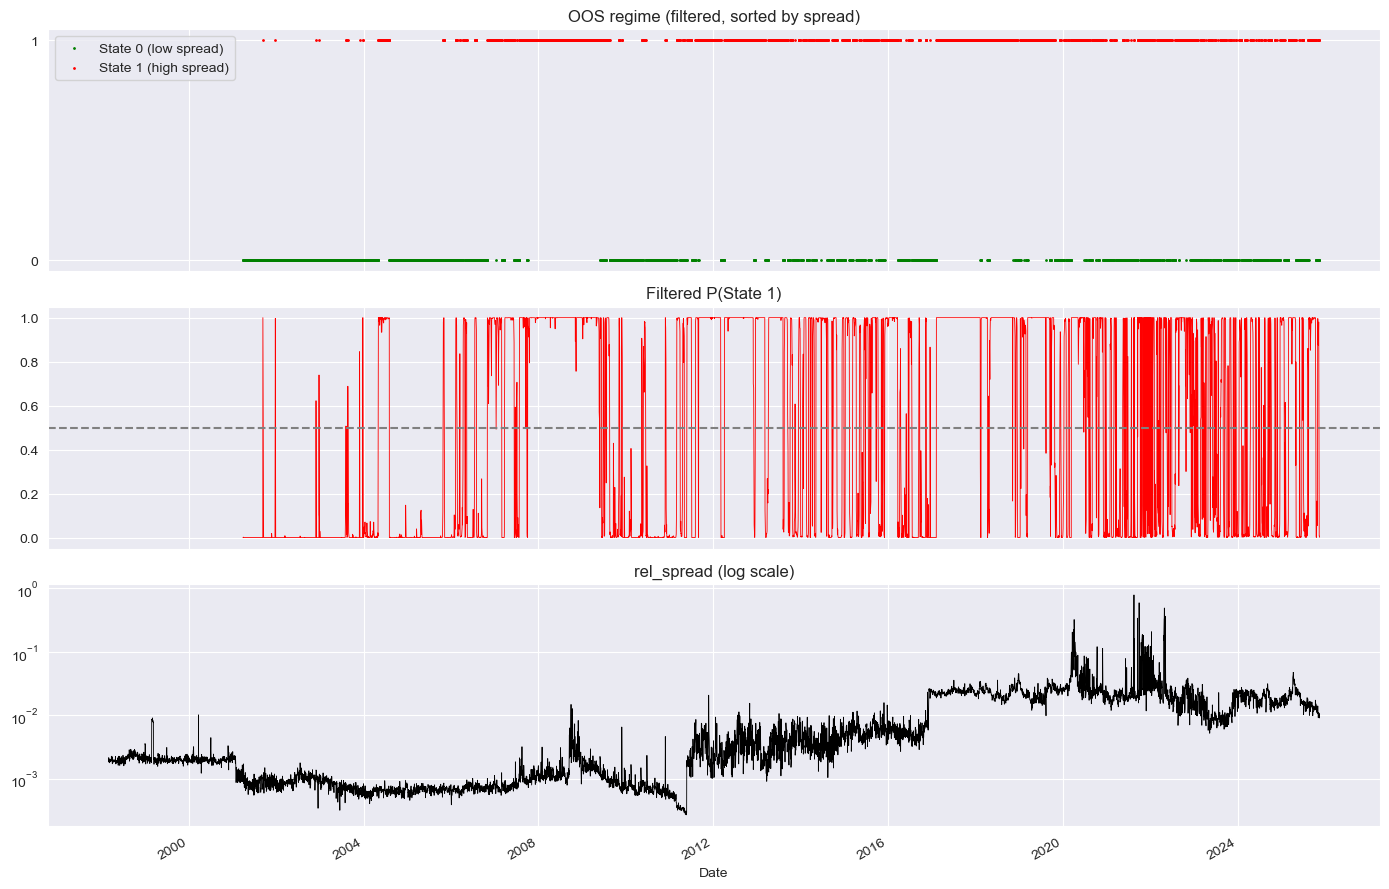

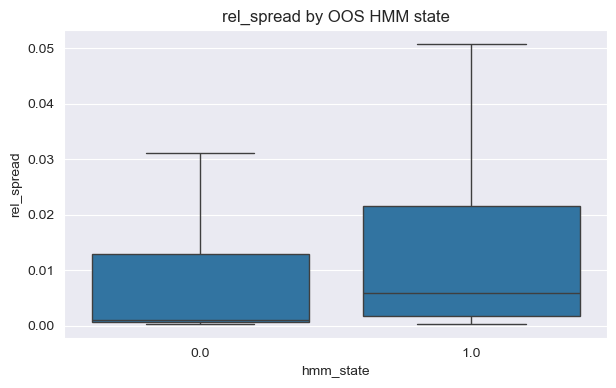

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for k, c, lab in [(0, 'green', 'State 0 (low spread)'), (1, 'red', 'State 1 (high spread)')]:
    s = df.index[df['hmm_state'] == k]
    axes[0].scatter(s, [k] * len(s), c=c, s=1, label=lab)
axes[0].set_yticks([0, 1]); axes[0].legend(loc='upper left'); axes[0].set_title('OOS regime (filtered, sorted by spread)')
df['prob_state_1'].plot(ax=axes[1], color='red', lw=0.6); axes[1].axhline(0.5, ls='--', c='gray')
axes[1].set_title('Filtered P(State 1)')
df['rel_spread'].plot(ax=axes[2], color='black', lw=0.6, logy=True); axes[2].set_title('rel_spread (log scale)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x='hmm_state', y='rel_spread', data=df.dropna(subset=['hmm_state']), ax=ax, showfliers=False)
ax.set_title('rel_spread by OOS HMM state'); plt.show()

## 5. Regression dataset

Target: `log(rel_spread)`. The spread is right-skewed and spans two orders of magnitude across the sample, so models are fitted
in log space and forecasts are transformed back with `exp()`; all accuracy metrics are computed on the spread level.

In [9]:
df['y'] = df['rel_spread']
df['log_y'] = np.log(df['y'])                        # modelling target; forecasts are mapped back with exp()
df['log_spread_lag1'] = np.log(df['spread_lag1'])
df['log_spread_lag2'] = np.log(df['spread_lag2'])
df['prob_state_1_lag1'] = df['prob_state_1'].shift(1)

# prob_state_0_lag1 is dropped: it equals 1 - prob_state_1_lag1 (perfect collinearity)
model_features = ['log_spread_lag1', 'log_spread_lag2', 'rv_5', 'rv_21', 'price_trend',
                  'log_volume_lag1', 'ami_lag1', 'pe_diff_lag1', 'pandemic_dummy', 'prob_state_1_lag1']

df_model = df.dropna(subset=model_features + ['y']).copy()
print("Rows for modelling:", len(df_model), "|", df_model.index.min().date(), "to", df_model.index.max().date())
print("Training-eligible rows (non-outlier):", int(df_model['train_ok'].sum()))

Rows for modelling: 6195 | 2001-03-29 to 2025-11-13
Training-eligible rows (non-outlier): 5744


## 6. Rolling time-series CV

For each refit date *i* (every `CV_STEP` days): history = previous `TRAIN_WINDOW` rows, outliers removed;
the last `VAL_WINDOW` rows are used for early stopping; the model is then refit on train+val with the chosen number of trees
and forecasts rows `[i, i+CV_STEP)`. Each forecast uses only features known at t-1.
Train/validation RMSE are in log units; OOS metrics are on the level scale.
`Linear (level y)` is the original specification (level target and level lags), kept for reference.

In [10]:
TREE_PARAMS = dict(max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=SEED)

def make_model(model_type, n_estimators=2000, early_stop=True):
    if model_type == 'xgb':
        return xgb.XGBRegressor(n_estimators=n_estimators, objective='reg:squarederror', eval_metric='rmse',
                                early_stopping_rounds=50 if early_stop else None, verbosity=0, n_jobs=4, **TREE_PARAMS)
    if model_type == 'lgb':
        return lgb.LGBMRegressor(n_estimators=n_estimators, num_leaves=8, subsample_freq=1, objective='regression',
                                 verbose=-1, n_jobs=4, **TREE_PARAMS)
    raise ValueError(model_type)


def rolling_cv(data, features, target='log_y', inverse=np.exp, level_col='y', train_window=TRAIN_WINDOW,
               val_window=VAL_WINDOW, step=CV_STEP, model_type='xgb', mask_col='train_ok'):
    # models are fitted on `target`; forecasts are mapped back with `inverse` and stored on the level scale
    preds, windows = [], []
    last_model = last_X = None
    for i in range(train_window, len(data), step):
        hist = data.iloc[i - train_window:i]
        if mask_col is not None:
            hist = hist[hist[mask_col]]
        train, val, test = hist.iloc[:-val_window], hist.iloc[-val_window:], data.iloc[i:i + step]
        Xtr, ytr = train[features].values, train[target].values
        Xva, yva = val[features].values, val[target].values
        Xte = test[features].values
        Xprod, yprod = np.vstack([Xtr, Xva]), np.concatenate([ytr, yva])
        best_iter, train_rmse, val_rmse = np.nan, np.nan, np.nan

        if model_type in ('xgb', 'lgb'):
            base = make_model(model_type)
            if model_type == 'xgb':
                base.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
                best_iter = base.best_iteration + 1
                val_rmse = base.evals_result()['validation_0']['rmse'][base.best_iteration]
            else:
                base.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric='rmse',
                         callbacks=[lgb.early_stopping(50, verbose=False)])
                best_iter = base.best_iteration_ or base.n_estimators
                val_rmse = base.best_score_['valid_0']['rmse']
            train_rmse = root_mean_squared_error(ytr, base.predict(Xtr))
            prod = make_model(model_type, n_estimators=int(best_iter), early_stop=False).fit(Xprod, yprod)
            y_pred = prod.predict(Xte)
        elif model_type == 'lin':
            scaler = StandardScaler().fit(Xtr)
            base = LinearRegression().fit(scaler.transform(Xtr), ytr)
            train_rmse = root_mean_squared_error(ytr, base.predict(scaler.transform(Xtr)))
            val_rmse = root_mean_squared_error(yva, base.predict(scaler.transform(Xva)))
            scaler = StandardScaler().fit(Xprod)
            prod = LinearRegression().fit(scaler.transform(Xprod), yprod)
            y_pred = prod.predict(scaler.transform(Xte))
        elif model_type == 'persistence':
            prod = None
            y_pred = test['spread_lag1'].values         # already on the level scale
        else:
            raise ValueError("model_type must be 'lin', 'xgb', 'lgb' or 'persistence'")

        if model_type != 'persistence':
            y_pred = inverse(y_pred)
        preds.append(pd.DataFrame({'y_true': test[level_col].values, 'y_pred': y_pred,
                                   'state': test['hmm_state'].values, 'block': i}, index=test.index))
        windows.append({'date': test.index[0], 'train_rmse': train_rmse, 'val_rmse': val_rmse, 'best_iter': best_iter})
        last_model, last_X = prod, hist[features]
    return pd.concat(preds), pd.DataFrame(windows).set_index('date'), (last_model, last_X)


results, win_stats, last_fit = {}, {}, {}
for name, mt in [('XGBoost', 'xgb'), ('LightGBM', 'lgb'), ('Linear', 'lin'), ('Persistence', 'persistence')]:
    print(f"Running {name} ...")
    results[name], win_stats[name], last_fit[name] = rolling_cv(df_model, model_features, model_type=mt)
level_features = ['spread_lag1', 'spread_lag2'] + model_features[2:]
results['Linear (level y)'], win_stats['Linear (level y)'], _ = rolling_cv(
    df_model, level_features, target='y', inverse=lambda v: v, model_type='lin')
print("Done. OOS forecasts per model:", len(results['XGBoost']))

Running XGBoost ...


Running LightGBM ...


Running Linear ...


Running Persistence ...


Done. OOS forecasts per model: 5695


## 7. Out-of-sample performance

In [11]:
def metrics(y_true, y_pred, y_bench=None):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mse = np.mean((y_true - y_pred) ** 2)
    out = {'RMSE': math.sqrt(mse), 'MAE': mean_absolute_error(y_true, y_pred),
           'R2': 1 - mse / np.var(y_true)}
    if y_bench is not None:
        out['Skill vs Persist'] = 1 - mse / np.mean((y_true - np.asarray(y_bench, float)) ** 2)
    return out

bench = results['Persistence']['y_pred']
rows = []
for name, r in results.items():
    m = metrics(r['y_true'], r['y_pred'], bench)
    w = win_stats[name]
    m.update({'Avg Train RMSE': w['train_rmse'].mean(), 'Avg Val RMSE': w['val_rmse'].mean()})
    m['Overfit Gap'] = m['Avg Val RMSE'] - m['Avg Train RMSE']
    rows.append(pd.Series(m, name=name))
comparison = pd.DataFrame(rows)
print(comparison.round(6).to_string())
best_model = comparison['RMSE'].idxmin()
print("Best model by OOS RMSE:", best_model)

# sub-period metrics (the Dec-2016 level shift dominates squared errors)
split = '2016-12-01'
per = {}
for name, r in results.items():
    for lab, part in [('before 2016-12', r.loc[:split]), ('from 2016-12', r.loc[split:])]:
        per[(lab, name)] = metrics(part['y_true'], part['y_pred'], bench.loc[part.index])
display(pd.DataFrame(per).T.round(6))

# for comparison with the original notebook, which deleted extreme-spread days from the test set as well
ok = df_model['train_ok']
excl = {name: metrics(r.loc[ok.loc[r.index], 'y_true'], r.loc[ok.loc[r.index], 'y_pred'],
                      bench.loc[r.index][ok.loc[r.index]])
        for name, r in results.items()}
print(f"Excluding {(~ok.loc[bench.index]).sum()} flagged outlier days from the test set:")
display(pd.DataFrame(excl).T.round(6))

                      RMSE       MAE        R2  Skill vs Persist  Avg Train RMSE  Avg Val RMSE  Overfit Gap
XGBoost           0.020815  0.003630  0.278878          0.190199        0.189889      0.271424     0.081536
LightGBM          0.020865  0.003568  0.275420          0.186316        0.206850      0.266689     0.059839
Linear            0.019596  0.003293  0.360854          0.282256        0.231184      0.248880     0.017696
Persistence       0.023130  0.003698  0.109507          0.000000             NaN           NaN          NaN
Linear (level y)  0.019980  0.003622  0.335565          0.253857        0.004647      0.004625    -0.000022
Best model by OOS RMSE: Linear


,,RMSE,MAE,R2,Skill vs Persist
before 2016-12,XGBoost,0.001333,0.000643,0.657026,0.183156
from 2016-12,XGBoost,0.033067,0.008202,0.071079,0.190216
before 2016-12,LightGBM,0.001324,0.000638,0.661733,0.194367
from 2016-12,LightGBM,0.033147,0.008051,0.066582,0.186296
before 2016-12,Linear,0.001261,0.000609,0.693077,0.269018
from 2016-12,Linear,0.031130,0.007400,0.176697,0.282288
before 2016-12,Persistence,0.001475,0.000714,0.580123,0.000000
from 2016-12,Persistence,0.036746,0.008265,-0.147122,0.000000
before 2016-12,Linear (level y),0.001237,0.000610,0.704506,0.296236
from 2016-12,Linear (level y),0.031743,0.008231,0.143963,0.253752


Excluding 416 flagged outlier days from the test set:


,RMSE,MAE,R2,Skill vs Persist
XGBoost,0.012314,0.002786,0.488253,0.547062
LightGBM,0.012323,0.002722,0.487535,0.546426
Linear,0.011303,0.002574,0.568816,0.618367
Persistence,0.018297,0.003172,-0.129838,0.000000
Linear (level y),0.011769,0.002901,0.532505,0.586229


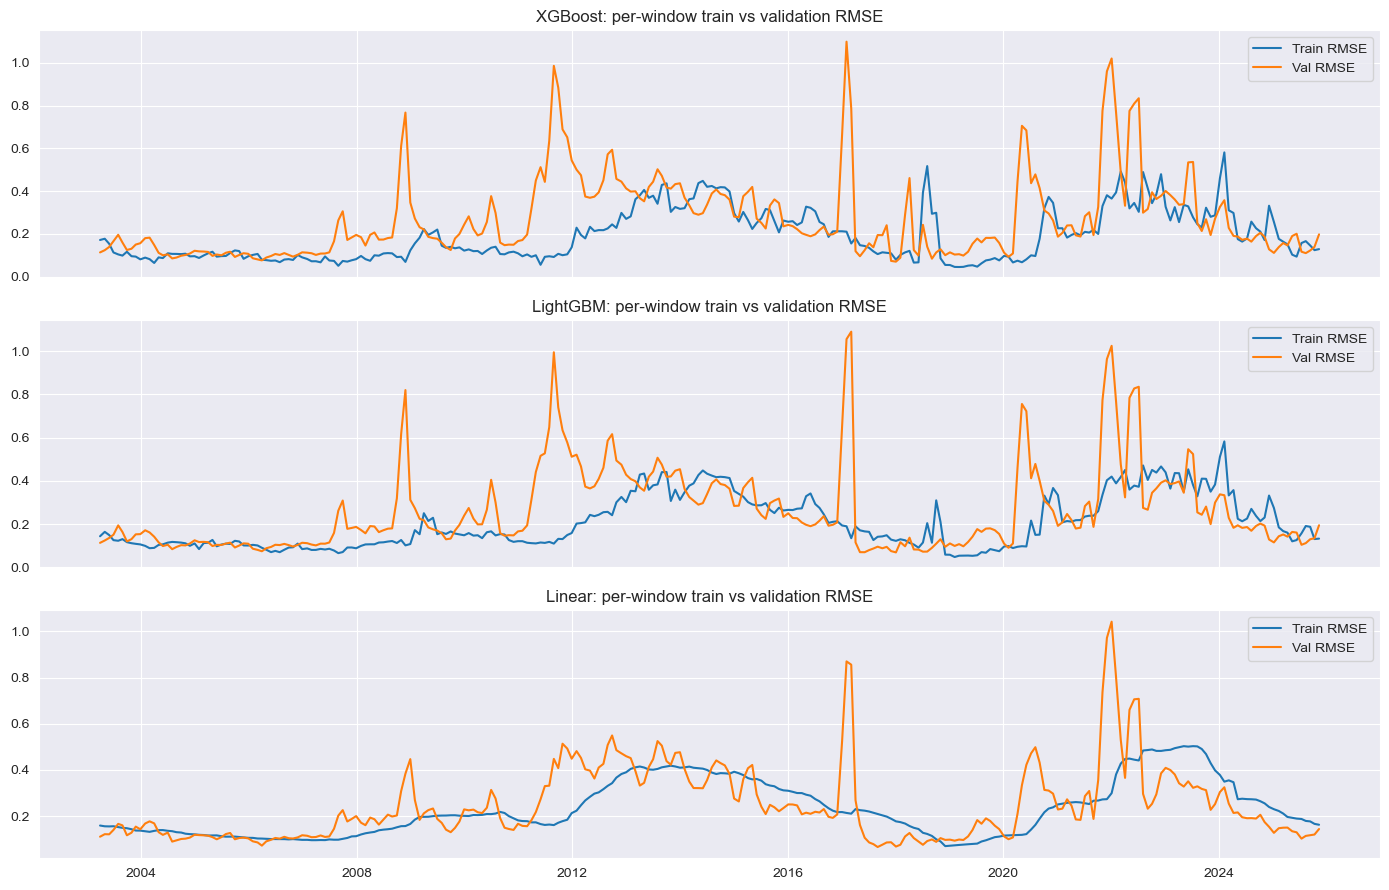

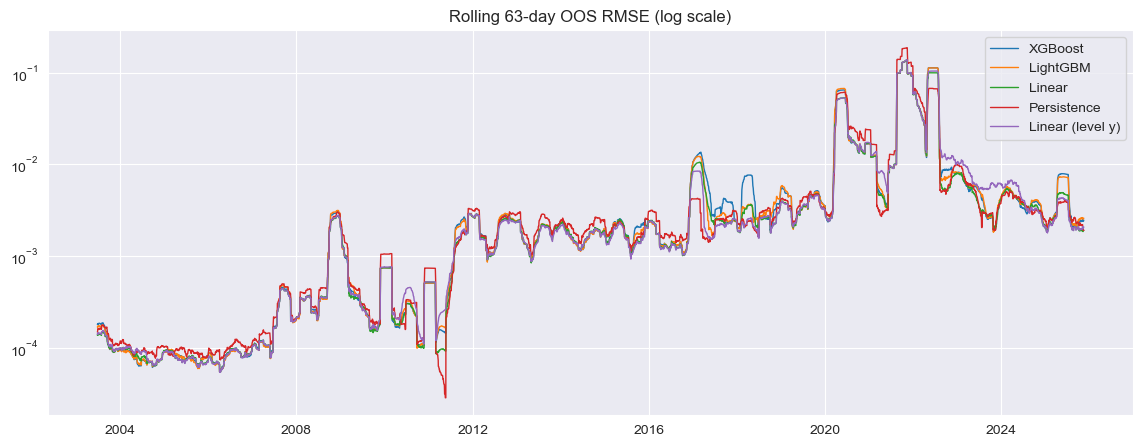

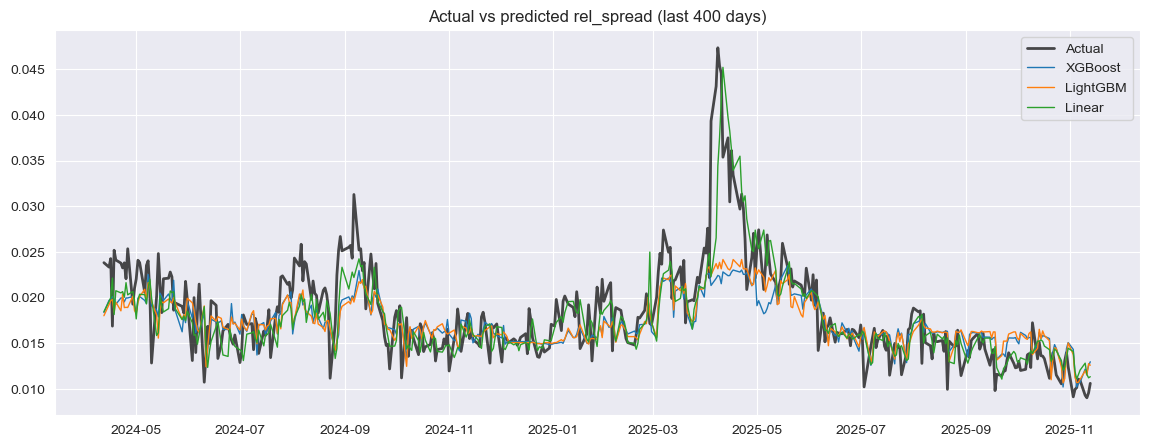

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, name in zip(axes, ['XGBoost', 'LightGBM', 'Linear']):
    w = win_stats[name]                                  # log units
    ax.plot(w.index, w['train_rmse'], label='Train RMSE'); ax.plot(w.index, w['val_rmse'], label='Val RMSE')
    ax.set_title(f'{name}: per-window train vs validation RMSE'); ax.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(14, 5))
for name, r in results.items():
    plt.plot(((r['y_true'] - r['y_pred']) ** 2).rolling(63).mean() ** 0.5, label=name, lw=1)
plt.yscale('log'); plt.legend(); plt.title('Rolling 63-day OOS RMSE (log scale)'); plt.show()

sel = slice(-400, None)
plt.figure(figsize=(14, 5))
r0 = results['XGBoost']
plt.plot(r0.index[sel], r0['y_true'].iloc[sel], label='Actual', color='black', lw=2, alpha=0.7)
for name in ['XGBoost', 'LightGBM', 'Linear']:
    plt.plot(results[name].index[sel], results[name]['y_pred'].iloc[sel], label=name, lw=1)
plt.legend(); plt.title('Actual vs predicted rel_spread (last 400 days)'); plt.show()

## 8. Diebold–Mariano test

Squared-error loss, Newey–West (Bartlett) long-run variance with lag ⌊T^{1/3}⌋, Harvey–Leybourne–Newbold small-sample correction, t(T-1) p-values.
Negative statistic ⇒ the first model has lower loss.

In [13]:
def diebold_mariano(y_true, y1, y2, h=1, power=2, lag=None):
    y_true, y1, y2 = (np.asarray(a, float) for a in (y_true, y1, y2))
    d = np.abs(y_true - y1) ** power - np.abs(y_true - y2) ** power
    T, dbar = len(d), d.mean()
    lag = int(np.floor(T ** (1 / 3))) if lag is None else lag
    gamma = lambda k: np.sum((d[:T - k] - dbar) * (d[k:] - dbar)) / T
    S = gamma(0) + 2 * sum((1 - k / (lag + 1)) * gamma(k) for k in range(1, lag + 1))
    dm = dbar / math.sqrt(S / T)
    dm_hln = dm * math.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return dm_hln, 2 * stats.t.sf(abs(dm_hln), df=T - 1)

y = results['Persistence']['y_true']
pairs = [('XGBoost', 'Persistence'), ('LightGBM', 'Persistence'), ('Linear', 'Persistence'),
         ('XGBoost', 'Linear'), ('LightGBM', 'Linear'), ('XGBoost', 'LightGBM'), ('Linear', 'Linear (level y)')]
dm_tab = pd.DataFrame([(a, b, *diebold_mariano(y, results[a]['y_pred'], results[b]['y_pred'])) for a, b in pairs],
                      columns=['Model A', 'Model B', 'DM (HLN)', 'p-value'])
display(dm_tab.round(4))

,Model A,Model B,DM (HLN),p-value
0,XGBoost,Persistence,-0.6560,0.5118
1,LightGBM,Persistence,-0.6439,0.5197
2,Linear,Persistence,-1.0753,0.2823
3,XGBoost,Linear,1.5624,0.1182
4,LightGBM,Linear,1.5921,0.1114
5,XGBoost,LightGBM,-0.6340,0.5261
6,Linear,Linear (level y),-1.7350,0.0828


## 9. SHAP — XGBoost model of the last rolling window

This is the model that actually produced the most recent forecasts (not a full-sample in-sample model). SHAP values are in log-spread units.

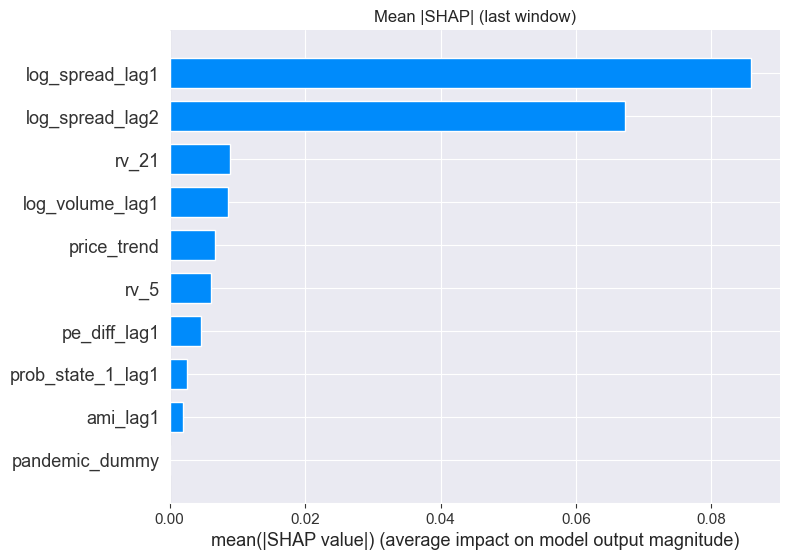

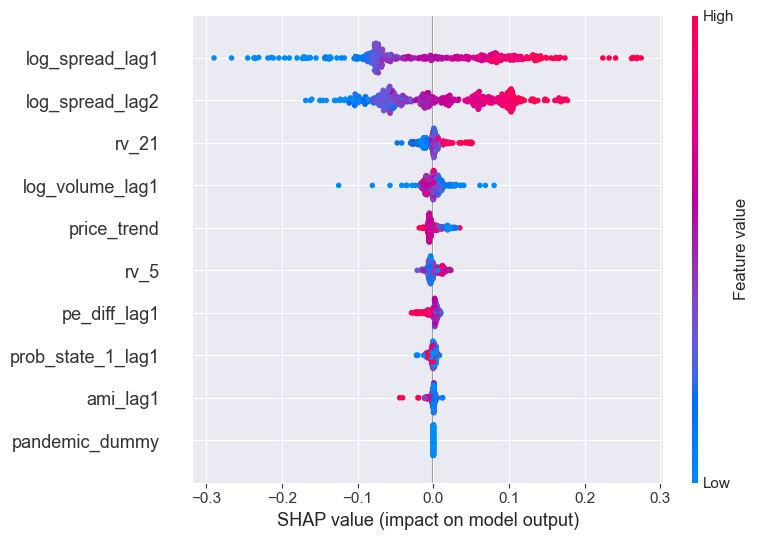

In [14]:
model_last, X_last = last_fit['XGBoost']
explainer = shap.TreeExplainer(model_last)
X_last = pd.DataFrame(X_last.values, columns=model_features, index=X_last.index)
sv = explainer(X_last)
shap.summary_plot(sv, X_last, plot_type='bar', show=False); plt.title('Mean |SHAP| (last window)'); plt.show()
shap.summary_plot(sv, X_last, show=False); plt.show()

## 10. Errors by regime and residual diagnostics

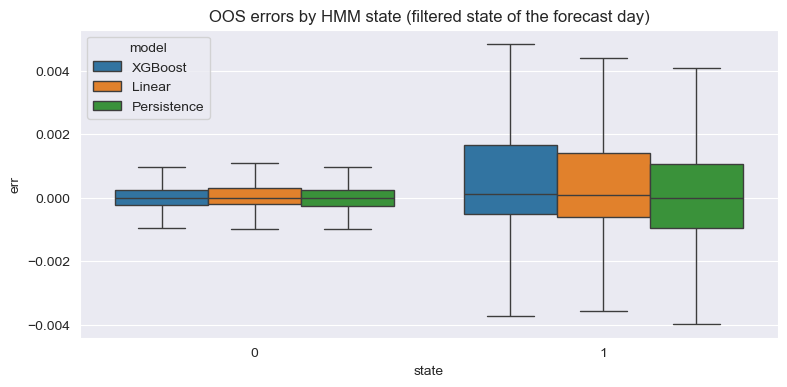

mean       std  count      RMSE
model       state                                     
Linear      0      0.000094  0.003401   2632  0.003401
            1      0.002937  0.026375   3063  0.026534
Persistence 0     -0.000922  0.017817   2632  0.017837
            1      0.000795  0.026851   3063  0.026858
XGBoost     0      0.000140  0.003656   2632  0.003658
            1      0.003581  0.027955   3063  0.028179

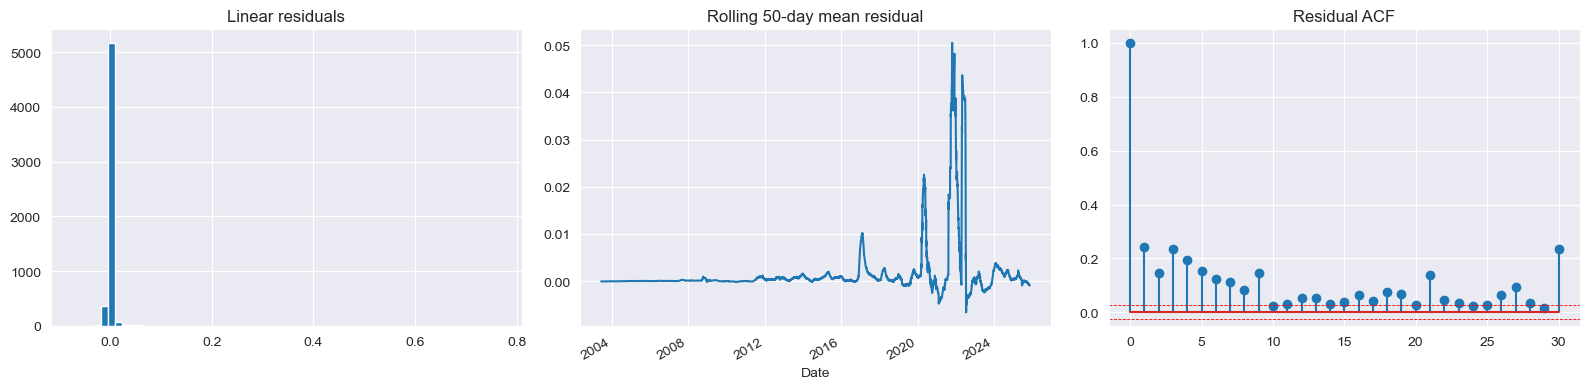

In [15]:
err_rows = []
for name in ['XGBoost', 'Linear', 'Persistence']:
    r = results[name].dropna(subset=['state'])
    err_rows.append(pd.DataFrame({'err': r['y_true'] - r['y_pred'], 'state': r['state'].astype(int), 'model': name}))
err_df = pd.concat(err_rows)

plt.figure(figsize=(9, 4))
sns.boxplot(x='state', y='err', hue='model', data=err_df, showfliers=False)
plt.title('OOS errors by HMM state (filtered state of the forecast day)'); plt.show()
display(err_df.groupby(['model', 'state'])['err'].agg(['mean', 'std', 'count',
        lambda e: np.sqrt(np.mean(e ** 2))]).rename(columns={'<lambda_0>': 'RMSE'}))

resid = results[best_model]['y_true'] - results[best_model]['y_pred']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(resid, bins=60); axes[0].set_title(f'{best_model} residuals')
resid.rolling(50).mean().plot(ax=axes[1], title='Rolling 50-day mean residual')
acf_vals = acf(resid, nlags=30, fft=True)
axes[2].stem(acf_vals); ci = 1.96 / np.sqrt(len(resid))
axes[2].axhline(ci, c='r', ls='--', lw=0.6); axes[2].axhline(-ci, c='r', ls='--', lw=0.6)
axes[2].set_title('Residual ACF')
plt.tight_layout(); plt.show()

## 11. Economic evaluation: spread-timing rule

A trader who can choose *when* to execute trades on day t only if that day's forecast spread is below the median of the
forecasts of the previous 60 days (a causal threshold). Cost is measured as the actual spread on the execution day divided by the
average actual spread of its 21-day block, so that the 2017 level shift does not dominate. Values below 1 mean the rule
executes on cheaper-than-average days; the oracle uses the realised spread and shows the upper bound.

In [16]:
def timing_cost(r, lookback=60):
    norm = r['y_true'] / r.groupby('block')['y_true'].transform('mean')
    thr = r['y_pred'].shift(1).rolling(lookback, min_periods=20).median()
    trade = r['y_pred'] <= thr
    return norm[trade].mean(), trade.mean()

econ = {}
for name, r in results.items():
    cost, frac = timing_cost(r)
    econ[name] = {'avg normalized cost': cost, 'share of days traded': frac}
r = results['XGBoost']
oracle = r.assign(y_pred=r['y_true'])
econ['Oracle (perfect foresight)'] = dict(zip(['avg normalized cost', 'share of days traded'], timing_cost(oracle)))
econ['Trade every day'] = {'avg normalized cost': 1.0, 'share of days traded': 1.0}
econ_df = pd.DataFrame(econ).T
econ_df['saving vs every day'] = 1 - econ_df['avg normalized cost']
display(econ_df.round(4))

,avg normalized cost,share of days traded,saving vs every day
XGBoost,0.9765,0.5164,0.0235
LightGBM,0.9771,0.5008,0.0229
Linear,0.9804,0.5169,0.0196
Persistence,0.9775,0.5176,0.0225
Linear (level y),0.9748,0.5031,0.0252
Oracle (perfect foresight),0.8616,0.5175,0.1384
Trade every day,1.0000,1.0000,0.0000


## 12. Does the HMM add predictive value?

### 12a. Ablation: the same rolling CV without `prob_state_1_lag1`

In [17]:
no_hmm = [f for f in model_features if f != 'prob_state_1_lag1']
ablation = {}
for name, mt in [('XGBoost', 'xgb'), ('LightGBM', 'lgb'), ('Linear', 'lin')]:
    ablation[name], _, _ = rolling_cv(df_model, no_hmm, model_type=mt)

rows = []
for name, r_wo in ablation.items():
    r_w = results[name]
    stat, p = diebold_mariano(r_w['y_true'], r_w['y_pred'], r_wo['y_pred'])
    rows.append({'model': name, 'R2 with HMM': metrics(r_w['y_true'], r_w['y_pred'])['R2'],
                 'R2 without HMM': metrics(r_wo['y_true'], r_wo['y_pred'])['R2'],
                 'DM (with vs without)': stat, 'p-value': p})
display(pd.DataFrame(rows).set_index('model').round(4))

,R2 with HMM,R2 without HMM,DM (with vs without),p-value
model,,,,
XGBoost,0.2789,0.2810,0.7995,0.4240
LightGBM,0.2754,0.2739,-0.3100,0.7565
Linear,0.3609,0.3570,-0.9434,0.3455


### 12b. Improved HMM variants

Three attempts to address why the baseline HMM is redundant:

* **local-z inputs** — each HMM input is standardised against its own past 63 days, so states capture *local* stress rather than the
  data-vendor eras (2011 / 2016 level shifts);
* **spread-dynamics inputs** — the HMM sees Δlog spread, |return| and Δlog volume, i.e. information that is not already a regressor;
* **regime interactions** — `prob_state_1_lag1 ×` the spread lags, so the persistence of the spread can differ between regimes
  (a two-step approximation of a Markov-switching AR model).

All variants are compared with the no-HMM specification on the same rows.

,model,spec,R2,MAE,DM vs no HMM,p-value
0,Linear,no HMM,0.3534,0.0033,NaN,NaN
1,Linear,baseline HMM,0.3575,0.0033,-0.9680,0.3331
2,Linear,local-z HMM,0.3554,0.0033,-0.9764,0.3289
3,Linear,dynamics HMM,0.3544,0.0033,-0.6373,0.5239
4,Linear,HMM + interactions,0.3455,0.0033,0.9563,0.3390
5,LightGBM,no HMM,0.2615,0.0036,NaN,NaN
6,LightGBM,baseline HMM,0.2634,0.0036,-0.3477,0.7281
7,LightGBM,local-z HMM,0.2642,0.0036,-0.8124,0.4166
8,LightGBM,dynamics HMM,0.2608,0.0036,0.5546,0.5792
9,LightGBM,HMM + interactions,0.2604,0.0036,0.3557,0.7221


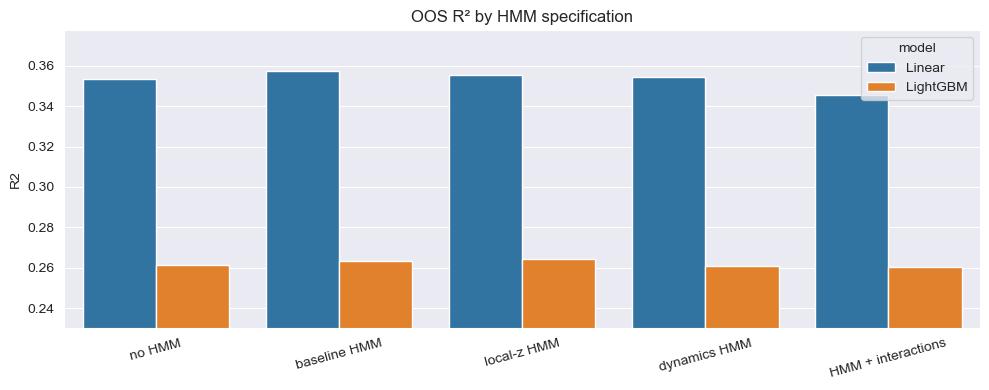

In [18]:
def local_z(s, w=63):
    return (s - s.shift(1).rolling(w).mean()) / s.shift(1).rolling(w).std()

hmm_inputs = {
    'local_z': pd.DataFrame({c: local_z(df[c]) for c in ['log_rel_spread', 'log_rv_5', 'log_volume', 'log_ami']})
                 .assign(price_trend=df['price_trend']),
    'dynamics': pd.DataFrame({'dlog_spread': df['log_rel_spread'].diff(), 'abs_return': df['abs_return'],
                              'dlog_volume': df['log_volume'].diff()}),
}
for key, F in hmm_inputs.items():
    P_v, _, _ = run_hmm(F)
    df_model[f'hmm_{key}_lag1'] = P_v['prob_state_1'].shift(1).reindex(df_model.index)

df_model['hmm_x_lag1'] = df_model['prob_state_1_lag1'] * df_model['log_spread_lag1']
df_model['hmm_x_dlag'] = df_model['prob_state_1_lag1'] * (df_model['log_spread_lag1'] - df_model['log_spread_lag2'])

variant_specs = {
    'no HMM':                no_hmm,
    'baseline HMM':          model_features,
    'local-z HMM':           no_hmm + ['hmm_local_z_lag1'],
    'dynamics HMM':          no_hmm + ['hmm_dynamics_lag1'],
    'HMM + interactions':    model_features + ['hmm_x_lag1', 'hmm_x_dlag'],
}
df_var = df_model.dropna(subset=['hmm_local_z_lag1', 'hmm_dynamics_lag1'])
var_res, rows = {}, []
for mt, mname in [('lin', 'Linear'), ('lgb', 'LightGBM')]:
    for lab, f in variant_specs.items():
        var_res[(mname, lab)], _, _ = rolling_cv(df_var, f, model_type=mt)
    ref = var_res[(mname, 'no HMM')]
    for lab in variant_specs:
        r = var_res[(mname, lab)]
        stat, p = (np.nan, np.nan) if lab == 'no HMM' else diebold_mariano(r['y_true'], r['y_pred'], ref['y_pred'])
        rows.append({'model': mname, 'spec': lab, 'R2': metrics(r['y_true'], r['y_pred'])['R2'],
                     'MAE': metrics(r['y_true'], r['y_pred'])['MAE'], 'DM vs no HMM': stat, 'p-value': p})
variant_tab = pd.DataFrame(rows)
display(variant_tab.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=variant_tab, x='spec', y='R2', hue='model', ax=ax)
ax.set_ylim(variant_tab['R2'].min() - 0.03, variant_tab['R2'].max() + 0.02)
ax.set_title('OOS R² by HMM specification'); ax.set_xlabel(''); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 13. Can the HMM improve forecast *uncertainty*?

Errors are about four times larger in state 1, so the regime might be more useful for interval forecasts than for point forecasts.
We build 90% intervals around the Linear (log-target) forecast, `log ŷ ± 1.645·σ_t`, where σ_t is estimated from **past** OOS residuals:

* **constant** — residual std over the past 250 days;
* **EWMA** — RiskMetrics exponentially weighted residual volatility (λ = 0.94);
* **HMM regime** — separate residual variances for the two regimes over the past 250 days (weighted by the filtered probability),
  mixed with today's regime probability; done for the baseline HMM, the local-z HMM and, as a non-HMM benchmark, a simple
  "rv_5 above its 1-year median" flag;
* **EWMA × HMM** — EWMA scaled by the HMM regime ratio.

Evaluation: coverage and the Gneiting–Raftery interval score (lower is better), which rewards narrow intervals and penalises misses.

In [19]:
from scipy.stats import norm

r = results['Linear'].copy()
r['e'] = np.log(r['y_true']) - np.log(r['y_pred'])              # OOS residual in log space
past_e = r['e'].shift(1)                                         # residual of day t is known only after day t
LB, ALPHA = 250, 0.10
z = norm.ppf(1 - ALPHA / 2)

def sigma_constant():
    return past_e.rolling(LB, min_periods=60).std()

def sigma_ewma(lam=0.94):
    return np.sqrt((past_e ** 2).ewm(alpha=1 - lam, min_periods=60).mean())

def sigma_regime(p):
    # p_t = P(high regime at t | info up to t-1)
    p_past, e2 = p.shift(1), past_e ** 2
    v_hi = (e2 * p_past).rolling(LB, min_periods=60).sum() / p_past.rolling(LB, min_periods=60).sum()
    v_lo = (e2 * (1 - p_past)).rolling(LB, min_periods=60).sum() / (1 - p_past).rolling(LB, min_periods=60).sum()
    return np.sqrt(p * v_hi + (1 - p) * v_lo)

p_base = df_model['prob_state_1_lag1'].reindex(r.index)
p_local = df_model['hmm_local_z_lag1'].reindex(r.index)
rv_flag = (df_model['rv_5'] > df_model['rv_5'].shift(1).rolling(252, min_periods=60).median()).astype(float).reindex(r.index)

sigmas = {
    'constant': sigma_constant(),
    'EWMA': sigma_ewma(),
    'rv_5 flag (non-HMM)': sigma_regime(rv_flag),
    'baseline HMM': sigma_regime(p_base),
    'local-z HMM': sigma_regime(p_local),
    'EWMA x local-z HMM': sigma_ewma() * sigma_regime(p_local) / sigma_constant(),
}
valid = pd.concat(sigmas, axis=1).notna().all(axis=1)
y_log, f_log = np.log(r['y_true']), np.log(r['y_pred'])

def interval_score(sig):
    lo, hi = f_log - z * sig, f_log + z * sig
    score = (hi - lo) + 2 / ALPHA * (lo - y_log).clip(lower=0) + 2 / ALPHA * (y_log - hi).clip(lower=0)
    return score[valid], ((y_log >= lo) & (y_log <= hi))[valid], (hi - lo)[valid]

rows, scores = [], {}
st = r.loc[valid, 'state']
for name, sig in sigmas.items():
    scores[name], cov, width = interval_score(sig)
    rows.append({'method': name, 'coverage': cov.mean(), 'coverage state 0': cov[st == 0].mean(),
                 'coverage state 1': cov[st == 1].mean(), 'avg width (log)': width.mean(),
                 'interval score': scores[name].mean()})
display(pd.DataFrame(rows).set_index('method').round(4))

# DM on the interval score: power=1 with a zero "truth" gives d_t = IS_a - IS_b
zero = np.zeros(valid.sum())
dm_rows = []
for name in ['rv_5 flag (non-HMM)', 'baseline HMM', 'local-z HMM', 'EWMA x local-z HMM']:
    for ref in ['constant', 'EWMA']:
        stat, p = diebold_mariano(zero, scores[name], scores[ref], power=1)
        dm_rows.append({'method': name, 'vs': ref, 'DM': stat, 'p-value': p})
display(pd.DataFrame(dm_rows).round(4))

,coverage,coverage state 0,coverage state 1,avg width (log),interval score
method,,,,,
constant,0.9013,0.9261,0.8805,0.9249,1.3661
EWMA,0.9075,0.9156,0.9008,0.9051,1.2280
rv_5 flag (non-HMM),0.9070,0.9285,0.8890,0.9369,1.3621
baseline HMM,0.9088,0.9234,0.8965,0.9344,1.3450
local-z HMM,0.9098,0.9296,0.8932,0.9518,1.3611
EWMA x local-z HMM,0.9113,0.9149,0.9083,0.9379,1.2467


,method,vs,DM,p-value
0,rv_5 flag (non-HMM),constant,-0.4582,0.6468
1,rv_5 flag (non-HMM),EWMA,4.5931,0.0000
2,baseline HMM,constant,-2.8139,0.0049
3,baseline HMM,EWMA,4.2411,0.0000
4,local-z HMM,constant,-0.6508,0.5152
5,local-z HMM,EWMA,4.5357,0.0000
6,EWMA x local-z HMM,constant,-3.9228,0.0001
7,EWMA x local-z HMM,EWMA,3.5166,0.0004


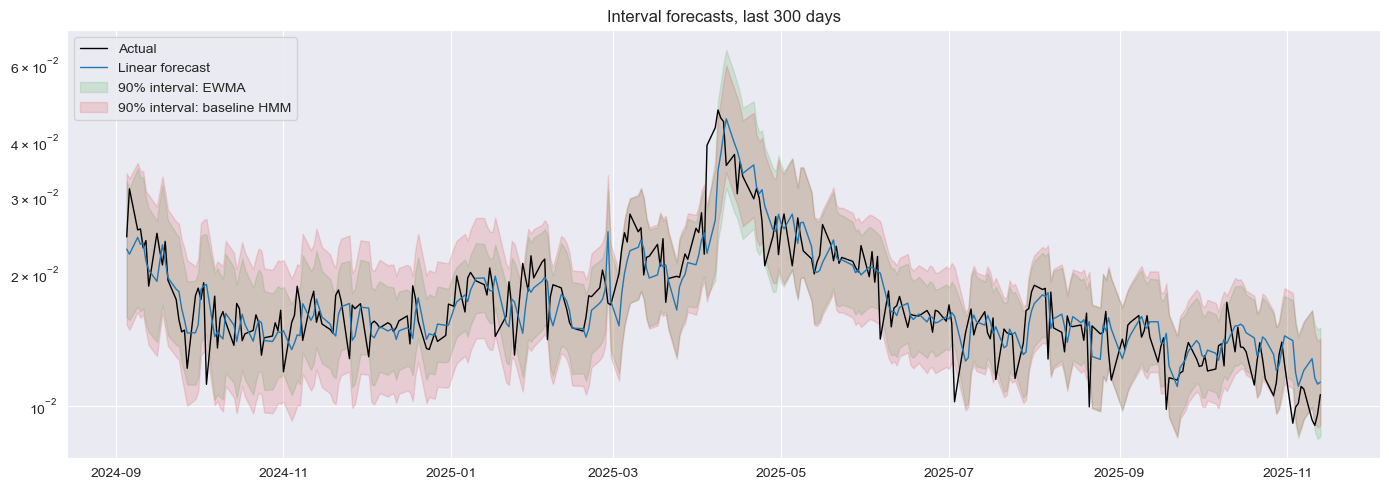

In [20]:
sel = r.index[valid][-300:]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sel, r.loc[sel, 'y_true'], color='black', lw=1, label='Actual')
ax.plot(sel, r.loc[sel, 'y_pred'], color='tab:blue', lw=1, label='Linear forecast')
for name, c in [('EWMA', 'tab:green'), ('baseline HMM', 'tab:red')]:
    s = sigmas[name].loc[sel]
    ax.fill_between(sel, np.exp(f_log.loc[sel] - z * s), np.exp(f_log.loc[sel] + z * s), color=c, alpha=0.15, label=f'90% interval: {name}')
ax.set_yscale('log'); ax.legend(loc='upper left'); ax.set_title('Interval forecasts, last 300 days')
plt.tight_layout(); plt.show()

## 14. Extensions

### 14a. Long-memory (HAR) and calendar features

* **HAR**: average log spread over the past 5, 22 and 63 days, the standard heterogeneous-autoregressive structure from the volatility
  literature; the baseline only uses the last two days.
* **Calendar**: pre/post-holiday, month start/end, monthly option expiry, quarterly "quad witching", day-of-week dummies.

Squared errors on the level scale are dominated by a few spike days, so we also report the mean absolute **log** error
(≈ average percentage error) and a DM test on squared log errors.

In [21]:
har_feats = ['har_5', 'har_22', 'har_63']
cal_feats = ['pre_holiday', 'post_holiday', 'month_end', 'month_start', 'opex', 'quad_witching',
             'dow_mon', 'dow_tue', 'dow_wed', 'dow_thu']
ext_specs = {'base': model_features, '+HAR': model_features + har_feats,
             '+calendar': model_features + cal_feats, '+HAR+calendar': model_features + har_feats + cal_feats}
df_ext = df_model.dropna(subset=har_feats)
bench_ext = df_ext['spread_lag1']

ext_res, rows = {}, []
for mt, mname in [('lin', 'Linear'), ('lgb', 'LightGBM')]:
    for lab, f in ext_specs.items():
        ext_res[(mname, lab)], _, _ = rolling_cv(df_ext, f, model_type=mt)
    ref = ext_res[(mname, 'base')]
    for lab in ext_specs:
        r = ext_res[(mname, lab)]
        m = metrics(r['y_true'], r['y_pred'], bench_ext.loc[r.index])
        row = {'model': mname, 'spec': lab, 'R2': m['R2'], 'Skill vs Persist': m['Skill vs Persist'],
               'MAE (log)': np.mean(np.abs(np.log(r['y_true']) - np.log(r['y_pred'])))}
        if lab != 'base':
            row['DM level p'] = diebold_mariano(r['y_true'], r['y_pred'], ref['y_pred'])[1]
            row['DM log'], row['DM log p'] = diebold_mariano(np.log(r['y_true']), np.log(r['y_pred']), np.log(ref['y_pred']))
        rows.append(row)
r = ext_res[('Linear', 'base')]
rows.append({'model': 'Persistence', 'spec': '-', 'R2': metrics(r['y_true'], bench_ext.loc[r.index])['R2'],
             'Skill vs Persist': 0.0, 'MAE (log)': np.mean(np.abs(np.log(r['y_true']) - np.log(bench_ext.loc[r.index])))})
ext_tab = pd.DataFrame(rows)
display(ext_tab.round(4))

# which calendar effects exist at all? in-sample OLS of the log spread change on calendar dummies (HAC t-stats)
import statsmodels.api as sm
dly = np.log(df_ext['y']) - df_ext['log_spread_lag1']
ols = sm.OLS(dly, sm.add_constant(df_ext[cal_feats])).fit(cov_type='HAC', cov_kwds={'maxlags': 10})
print("Calendar effects on daily change of log spread (in-sample, HAC):")
print(pd.DataFrame({'coef': ols.params, 't': ols.tvalues}).drop('const').round(3).to_string())

,model,spec,R2,Skill vs Persist,MAE (log),DM level p,DM log,DM log p
0,Linear,base,0.3609,0.2823,0.2100,NaN,NaN,NaN
1,Linear,+HAR,0.3595,0.2808,0.1933,0.9348,-3.6861,0.0002
2,Linear,+calendar,0.3605,0.2819,0.2094,0.8293,-0.4589,0.6463
3,Linear,+HAR+calendar,0.3594,0.2806,0.1930,0.9292,-3.5382,0.0004
4,LightGBM,base,0.2754,0.1863,0.2293,NaN,NaN,NaN
5,LightGBM,+HAR,0.2918,0.2047,0.2214,0.0372,-2.4186,0.0156
6,LightGBM,+calendar,0.2731,0.1837,0.2277,0.3854,-1.8283,0.0676
7,LightGBM,+HAR+calendar,0.2875,0.1999,0.2202,0.1034,-2.4595,0.0139
8,Persistence,-,0.1095,0.0000,0.2205,NaN,NaN,NaN


Calendar effects on daily change of log spread (in-sample, HAC):
                coef      t
pre_holiday    0.060  2.365
post_holiday   0.002  0.050
month_end      0.010  0.387
month_start   -0.081 -3.330
opex          -0.062 -2.274
quad_witching  0.069  1.757
dow_mon        0.004  0.172
dow_tue        0.030  1.724
dow_wed        0.023  1.321
dow_thu        0.032  1.847


### 14b. A more useful target: predicting spread spikes

For execution, knowing *which days to avoid* is often more useful than the exact spread. Define a spike as
`log spread_t` above the 90th percentile of the **past** 252 days, and forecast P(spike_t) with information up to t-1.
Rolling refit every 21 days on the previous 1,000 days. Metrics: ROC-AUC, average precision, Brier score,
and precision among the 10% of days with the highest predicted risk. Naive benchmarks: yesterday's spike flag and
yesterday's distance to today's threshold. AUC differences use a 21-day block bootstrap.
Note: the vendor level shifts (2011, 2016) also show up as runs of "spikes" until the rolling threshold catches up.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, average_precision_score

log_spread = np.log(df['rel_spread'])
spike_thr = log_spread.shift(1).rolling(252, min_periods=126).quantile(0.9)
df['spike'] = (log_spread > spike_thr).astype(float).where(spike_thr.notna())
df['spike_lag1'] = df['spike'].shift(1)
df['dist_to_thr'] = log_spread.shift(1) - spike_thr
for c in ['spike', 'spike_lag1', 'dist_to_thr']:
    df_ext[c] = df[c].reindex(df_ext.index)
df_clf = df_ext.dropna(subset=['spike', 'spike_lag1', 'dist_to_thr'])
print(f"Spike base rate: {df_clf['spike'].mean():.3f} over {len(df_clf)} days")


def rolling_clf(data, features, model='logit', train_window=1000, step=21):
    out = []
    for i in range(train_window, len(data), step):
        tr, te = data.iloc[i - train_window:i], data.iloc[i:i + step]
        Xtr, ytr, Xte = tr[features].values, tr['spike'].values, te[features].values
        if ytr.sum() < 10:
            p = np.full(len(te), ytr.mean())
        elif model == 'logit':
            sc = StandardScaler().fit(Xtr)
            p = LogisticRegression(max_iter=2000).fit(sc.transform(Xtr), ytr).predict_proba(sc.transform(Xte))[:, 1]
        else:
            clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, num_leaves=8, subsample=0.8,
                                     subsample_freq=1, colsample_bytree=0.8, min_child_samples=30,
                                     random_state=SEED, verbose=-1, n_jobs=4)
            p = clf.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
        out.append(pd.DataFrame({'y': te['spike'].values, 'p': p, 'state': te['hmm_state'].values}, index=te.index))
    return pd.concat(out)


def clf_metrics(r, is_prob=True):
    top = r.nlargest(int(len(r) * 0.1), 'p')
    return {'AUC': roc_auc_score(r['y'], r['p']), 'Avg precision': average_precision_score(r['y'], r['p']),
            'Brier': brier_score_loss(r['y'], r['p']) if is_prob else np.nan,
            'Precision@top10%': top['y'].mean(), 'Base rate': r['y'].mean()}


clf_base = no_hmm + ['spike_lag1', 'dist_to_thr']
clf_specs = {
    'logit, no HMM':        ('logit', clf_base),
    'logit, +HMM':          ('logit', clf_base + ['prob_state_1_lag1']),
    'logit, +HMM+HAR+cal':  ('logit', clf_base + ['prob_state_1_lag1'] + har_feats + cal_feats),
    'LGB, no HMM':          ('lgb', clf_base),
    'LGB, +HMM':            ('lgb', clf_base + ['prob_state_1_lag1']),
    'LGB, +HMM+HAR+cal':    ('lgb', clf_base + ['prob_state_1_lag1'] + har_feats + cal_feats),
}
clf_res = {lab: rolling_clf(df_clf, f, m) for lab, (m, f) in clf_specs.items()}
idx = clf_res['logit, no HMM'].index
for col in ['spike_lag1', 'dist_to_thr']:
    clf_res[f'naive: {col}'] = clf_res['logit, no HMM'][['y', 'state']].assign(p=df_clf.loc[idx, col])

clf_tab = pd.DataFrame({lab: clf_metrics(r, is_prob=not lab.startswith('naive: dist')) for lab, r in clf_res.items()}).T
display(clf_tab.round(4))

rng = np.random.default_rng(SEED)
def auc_diff_ci(a, b, B=1000, block=21):
    n = len(a); diffs = []
    for _ in range(B):
        ix = np.concatenate([np.arange(s, s + block) for s in rng.integers(0, n - block, n // block)])
        y = a['y'].values[ix]
        if y.min() != y.max():
            diffs.append(roc_auc_score(y, a['p'].values[ix]) - roc_auc_score(y, b['p'].values[ix]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return roc_auc_score(a['y'], a['p']) - roc_auc_score(b['y'], b['p']), lo, hi

pairs = [('logit, no HMM', 'naive: dist_to_thr'), ('logit, +HMM+HAR+cal', 'naive: dist_to_thr'), ('logit, +HMM', 'logit, no HMM'), ('LGB, +HMM', 'LGB, no HMM'),
         ('logit, +HMM+HAR+cal', 'logit, +HMM'), ('LGB, +HMM+HAR+cal', 'logit, +HMM+HAR+cal')]
display(pd.DataFrame([(a, b, *auc_diff_ci(clf_res[a], clf_res[b])) for a, b in pairs],
                     columns=['A', 'B', 'AUC diff', '95% CI low', '95% CI high']).round(4))

Spike base rate: 0.138 over 6195 days


,AUC,Avg precision,Brier,Precision@top10%,Base rate
"logit, no HMM",0.8263,0.5475,0.0962,0.6069,0.1519
"logit, +HMM",0.8233,0.5447,0.0966,0.6146,0.1519
"logit, +HMM+HAR+cal",0.8412,0.5644,0.0952,0.6185,0.1519
"LGB, no HMM",0.8127,0.5045,0.1020,0.5819,0.1519
"LGB, +HMM",0.8107,0.5011,0.1023,0.5703,0.1519
"LGB, +HMM+HAR+cal",0.8137,0.4936,0.1030,0.5684,0.1519
naive: spike_lag1,0.7243,0.3544,0.1421,0.5183,0.1519
naive: dist_to_thr,0.8330,0.5321,NaN,0.6224,0.1519


,A,B,AUC diff,95% CI low,95% CI high
0,"logit, no HMM",naive: dist_to_thr,-0.0067,-0.0225,0.0096
1,"logit, +HMM+HAR+cal",naive: dist_to_thr,0.0083,-0.0107,0.0269
2,"logit, +HMM","logit, no HMM",-0.0030,-0.0071,0.0008
3,"LGB, +HMM","LGB, no HMM",-0.0020,-0.0074,0.0032
4,"logit, +HMM+HAR+cal","logit, +HMM",0.0179,0.0047,0.0311
5,"LGB, +HMM+HAR+cal","logit, +HMM+HAR+cal",-0.0275,-0.0451,-0.0115


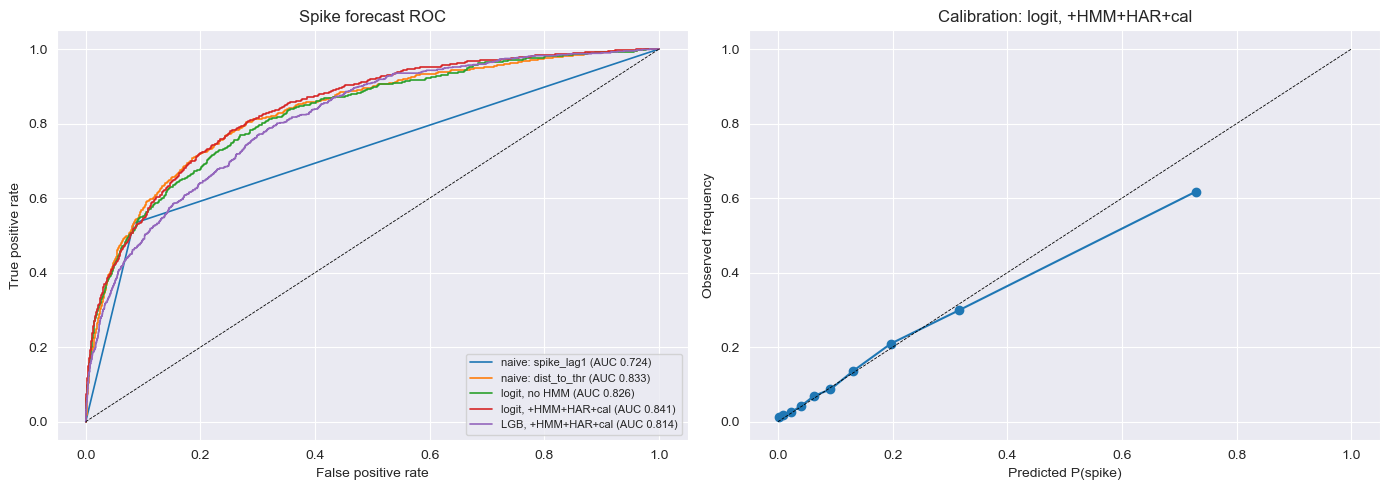

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for lab in ['naive: spike_lag1', 'naive: dist_to_thr', 'logit, no HMM', 'logit, +HMM+HAR+cal', 'LGB, +HMM+HAR+cal']:
    r = clf_res[lab]
    fpr, tpr, _ = roc_curve(r['y'], r['p'])
    axes[0].plot(fpr, tpr, lw=1.2, label=f"{lab} (AUC {roc_auc_score(r['y'], r['p']):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.6); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('Spike forecast ROC'); axes[0].legend(fontsize=8)

best_clf = clf_tab.drop(index=[i for i in clf_tab.index if i.startswith('naive')])['AUC'].idxmax()
r = clf_res[best_clf].copy()
r['bin'] = pd.qcut(r['p'], 10, labels=False, duplicates='drop')
cal = r.groupby('bin').agg(pred=('p', 'mean'), obs=('y', 'mean'))
axes[1].plot(cal['pred'], cal['obs'], marker='o'); axes[1].plot([0, 1], [0, 1], 'k--', lw=0.6)
axes[1].set_xlabel('Predicted P(spike)'); axes[1].set_ylabel('Observed frequency'); axes[1].set_title(f'Calibration: {best_clf}')
plt.tight_layout(); plt.show()

## 15. Summary

**Data.** Two data issues matter more than any modelling choice: (i) the vendor fills exchange holidays with a copy of the previous
day (≈250 rows, removed); (ii) the level of the index bid/ask jumps about 6x in June 2011 and 4x in December 2016, most likely a
methodology change rather than a change in SPX liquidity.

**Point forecasts (Sections 6–8, 14a).**
* After removing look-ahead bias, the best model is a linear regression on `log(spread)` (OOS R² ≈ 0.36, MSE about 28% below
  the persistence forecast). Gradient boosting does not beat the linear model; the original R² ≈ 0.89 was an artefact of leakage.
* Adding HAR long-memory features (5/22/63-day average log spread) significantly reduces typical-day errors
  (mean absolute log error ≈ 0.21 → 0.19, DM p < 0.001), i.e. roughly 12% below persistence on a typical day.
  Level-scale R² hardly moves because it is dominated by a few spike days.
* Calendar effects exist in-sample (spreads are wider before holidays and narrower at the start of the month and on option-expiry
  days), but they are small relative to daily noise and do not improve out-of-sample forecasts.

**HMM (Sections 4, 10, 12, 13).**
* The rolling HMM identifies persistent regimes (expected duration ≈ 20 days); forecast errors are several times larger in the
  high-spread regime, so the regime is a useful *risk flag*.
* As a predictor it adds no out-of-sample value for point forecasts, spike classification, or (relative to a simple EWMA of past
  residuals) interval forecasts — the information it summarises is already available to the models directly.

**Spike forecasting (Section 14b).** Predicting whether tomorrow's spread exceeds its past-year 90th percentile is feasible
(AUC ≈ 0.84; among the 10% of days flagged as riskiest about 60% are spikes, versus a base rate of about 15%), but most of this comes
from how close yesterday's spread already was to the threshold; the full logistic model improves on that naive rule only marginally.

**Takeaways.** Simple, well-specified linear models in log space with long-memory features dominate; regime models are best used
descriptively. Natural next steps are adding VIX, and moving to a tradable instrument (SPY / ES futures) or a cross-section of
stocks, where the spread is a real transaction cost and the larger sample gives non-linear models room to help.